<a href="https://colab.research.google.com/github/joseaespinosa02/glassdoor-nlp-dhl/blob/main/Glassdoor_DHL_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diagnóstico de marca empleadora — DHL Supply Chain vs. peers
## Sentimiento (DistilBERT) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar puntos fuertes y áreas de mejora de **DHL Supply Chain** como empleador a partir de Glassdoor, comparados con sus competidores directos.

**Peers:** UPS, FedEx, MAERSK, DB-Schenker y Kuehne+Nagel. Todos son operadores logísticos globales (paquetería, freight forwarding, contract logistics) que compiten por el mismo talento: operarios de almacén y transporte, supervisores de operaciones, planificadores y perfiles de supply chain. Todos superan las 300 reseñas.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic |
| 4 | Comparación con peers (balance neto) |
| 5 | Empleados actuales vs. antiguos |
| 6 | Matriz de priorización y recomendaciones |

In [28]:
# Colab (Entorno > Cambiar tipo de entorno > GPU). transformers ya viene instalado; BERTopic no.
!pip install -q bertopic sentence-transformers

---
## 0. Carga y preparación

In [29]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

TARGET = 'DHL-Supply-Chain'
# Solo la entidad 'DHL-Supply-Chain': hay otras (DHL, DHL-Global-Forwarding, Deutsche-Post-&-DHL)
# que son negocios distintos (paquetería/forwarding); mezclarlas diluiría el diagnóstico.
PEERS = ['UPS', 'FedEx', 'MAERSK', 'DB-Schenker', 'Kuehne+Nagel']
FIRMS = [TARGET] + PEERS

# Tope de 2.000 reseñas por empresa con semilla fija: UPS tiene ~17.500 y dominaría
# el modelo de topics conjunto; además acota el tiempo de DistilBERT/BERTopic.
MAX_POR_EMPRESA = 2000
SEED = 42

# Localización del dataset: carpeta actual o Google Drive (en Colab subir 286 MB por el panel es lento,
# por eso se admite tenerlo en "Mi unidad" y montar Drive).
import os
RUTA = 'glassdoor_reviews_hr.parquet'
if not os.path.exists(RUTA):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        RUTA = '/content/drive/MyDrive/glassdoor_reviews_hr.parquet'
    except ImportError:
        pass
assert os.path.exists(RUTA), f'No encuentro el dataset en {RUTA}: súbelo a la carpeta de trabajo o a Mi unidad de Google Drive'

raw = pd.read_parquet(RUTA, filters=[('firm', 'in', FIRMS)])
print('Reseñas disponibles por empresa:')
print(raw['firm'].value_counts())
print('\nNulos por columna:\n', raw.isna().sum())

# DECISIÓN: DHL-Supply-Chain solo tiene reseñas hasta junio 2021; los peers llegan a 2023.
# Recortamos todas las empresas a la misma ventana para que la comparación sea justa:
# si no, compararíamos a DHL (2018-2021) con peers que incluyen la crisis logística de 2022.
# Alternativa descartada: unir entidades DHL (paquetería/forwarding = otro negocio y otro perfil).
raw['date_review'] = pd.to_datetime(raw['date_review'])
FIN = raw.loc[raw['firm'] == TARGET, 'date_review'].max()
raw = raw[raw['date_review'] <= FIN]
print(f'\nVentana común: {raw.date_review.min():%Y-%m-%d} -> {FIN:%Y-%m-%d}')
print(raw['firm'].value_counts())

Reseñas disponibles por empresa:
firm
UPS                 17503
FedEx                5039
MAERSK               2976
DHL-Supply-Chain     1687
DB-Schenker          1312
Kuehne+Nagel          926
Name: count, dtype: int64

Nulos por columna:
 firm              0
date_review       0
current           0
overall_rating    0
recommend         0
pros              0
cons              0
dtype: int64

Ventana común: 2018-07-27 -> 2021-06-05
firm
UPS                 8438
FedEx               2669
DHL-Supply-Chain    1687
MAERSK              1304
DB-Schenker          602
Kuehne+Nagel         471
Name: count, dtype: int64


In [30]:
# Limpieza previa al muestreo
for col in ['pros', 'cons']:
    raw[col] = raw[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

n0 = len(raw)
raw = raw.drop_duplicates(subset=['firm', 'pros', 'cons'])           # duplicados exactos
raw = raw[(raw['pros'].str.len() >= 3) & (raw['cons'].str.len() >= 3)]  # textos vacíos o 'nan'
print(f'Eliminadas {n0 - len(raw):,} filas duplicadas o sin texto')

df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in raw.groupby('firm')], ignore_index=True)
print(f'Muestra de trabajo: {len(df):,} reseñas')
print(df['firm'].value_counts())

Eliminadas 2 filas duplicadas o sin texto
Muestra de trabajo: 8,063 reseñas
firm
UPS                 2000
FedEx               2000
DHL-Supply-Chain    1687
MAERSK              1303
DB-Schenker          602
Kuehne+Nagel         471
Name: count, dtype: int64


La columna `current` mezcla situación y antigüedad (`"Former Employee, more than 3 years"`). La separo en dos variables y traduzco `recommend` (v = sí, o = sin opinión, x = no).

In [31]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'): return 'Actual'
    if s.startswith('former'):  return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

df['situacion']  = df['current'].map(situacion)
df['antiguedad'] = df['current'].map(antiguedad)
df['recomienda'] = df['recommend'].map({'v': 'Sí', 'o': 'Neutral', 'x': 'No'})
df['date_review'] = pd.to_datetime(df['date_review'])
df['anio'] = df['date_review'].dt.year
df['es_target'] = np.where(df['firm'] == TARGET, TARGET, 'Peers')

print(df['situacion'].value_counts(), '\n')
print(df['antiguedad'].value_counts())
df[['firm','date_review','situacion','antiguedad','overall_rating','recomienda','pros','cons']].head()

situacion
Actual     4543
Antiguo    3520
Name: count, dtype: int64 

antiguedad
n/d              3046
more than 1y     1428
less than 1y     1375
more than 3y      964
more than 5y      557
more than 10y     434
more than 8y      259
Name: count, dtype: int64


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,DB-Schenker,2019-05-05,Antiguo,n/d,3.0,Sí,Big Multi-National Company in the logistics industry.,A long working hour and company politics.
1,DB-Schenker,2021-01-20,Antiguo,n/d,4.0,Neutral,many breaks for the job,long hours in a day
2,DB-Schenker,2021-05-04,Antiguo,more than 1y,2.0,No,- Decent benefits - Salary increase,- Extremely bad management - Lack of transparency - People are not promoted fairly - Employees of the SSC are treated as second rate employees - Few opportunities to grow
3,DB-Schenker,2019-02-28,Actual,n/d,3.0,Neutral,- international company - great people working with our customers,- highly political - too many prioritized topics
4,DB-Schenker,2019-10-28,Antiguo,less than 1y,3.0,No,- environment and supervisors - company lunches,- wages (below industry) - parking a huge issue (had to arrive 30 mins early just to find a place to park)


---
## 1. EDA
### 1.1 Resumen por empresa

In [32]:
resumen = (df.groupby('firm')
    .agg(n_resenas=('firm', 'size'),
         rating_medio=('overall_rating', 'mean'),
         pct_recomienda=('recommend', lambda s: (s == 'v').mean() * 100),
         pct_no_recomienda=('recommend', lambda s: (s == 'x').mean() * 100),
         pct_actuales=('situacion', lambda s: (s == 'Actual').mean() * 100))
    .round(2).sort_values('rating_medio', ascending=False))
# % recomienda calculado sobre el total (incluye 'sin opinión'), igual para todas las firmas
resumen

,n_resenas,rating_medio,pct_recomienda,pct_no_recomienda,pct_actuales
firm,,,,,
MAERSK,1303,3.98,59.09,14.35,55.49
FedEx,2000,3.72,46.25,17.90,57.80
Kuehne+Nagel,471,3.53,53.29,26.96,60.72
DHL-Supply-Chain,1687,3.52,44.16,25.84,57.50
UPS,2000,3.49,40.50,26.50,54.20
DB-Schenker,602,3.24,39.87,34.55,53.82


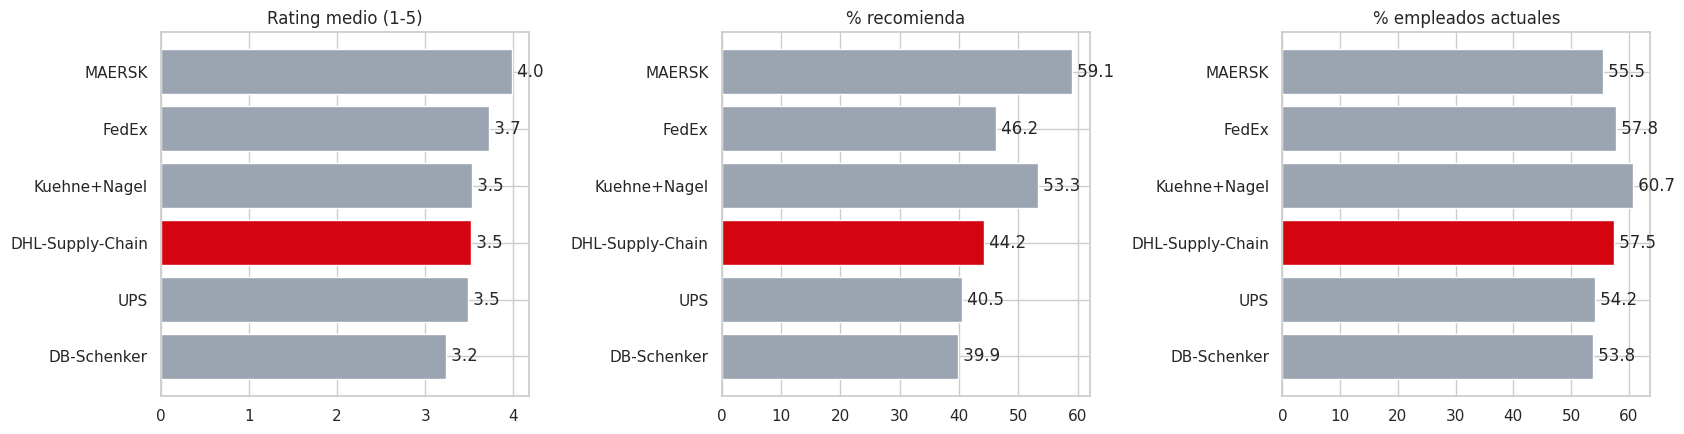

In [33]:
orden = resumen.index.tolist()
colores = ['#D40511' if f == TARGET else '#9aa5b1' for f in orden]   # rojo DHL para destacar
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, tit in zip(axes, ['rating_medio', 'pct_recomienda', 'pct_actuales'],
                        ['Rating medio (1-5)', '% recomienda', '% empleados actuales']):
    ax.barh(orden, resumen[col], color=colores)
    ax.set_title(tit); ax.invert_yaxis()
    for i, v in enumerate(resumen[col]): ax.text(v, i, f' {v:.1f}', va='center')
plt.tight_layout(); plt.show()

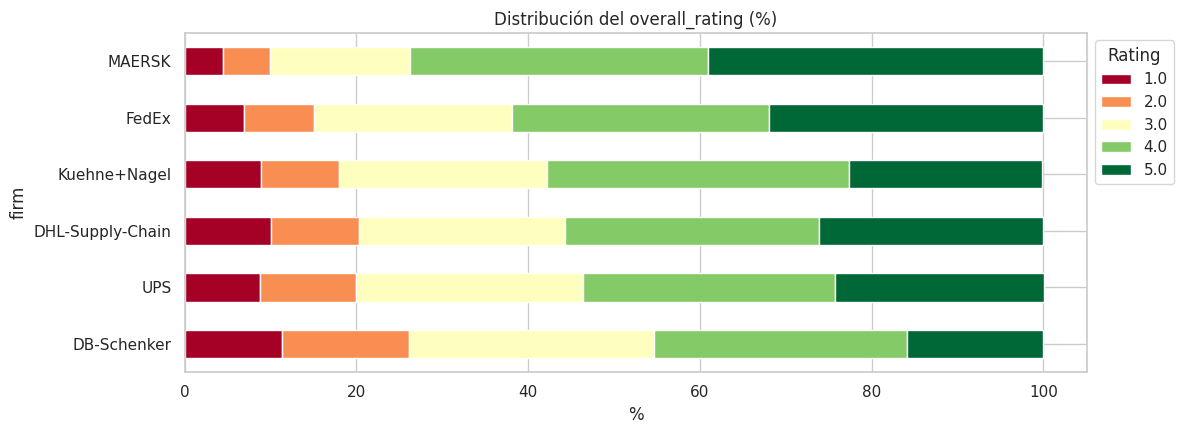

overall_rating,1.0,2.0,3.0,4.0,5.0
firm,,,,,
MAERSK,4.5,5.4,16.3,34.8,39.0
FedEx,6.9,8.2,23.0,29.9,32.0
Kuehne+Nagel,8.9,9.1,24.2,35.2,22.5
DHL-Supply-Chain,10.1,10.2,24.0,29.6,26.1
UPS,8.8,11.2,26.4,29.4,24.3
DB-Schenker,11.3,14.8,28.6,29.4,15.9


In [34]:
# Distribución del rating: ¿la media esconde polarización?
dist = pd.crosstab(df['firm'], df['overall_rating'], normalize='index').mul(100).round(1).loc[orden]
dist.plot(kind='barh', stacked=True, figsize=(12, 4.5), colormap='RdYlGn')
plt.title('Distribución del overall_rating (%)'); plt.xlabel('%'); plt.gca().invert_yaxis()
plt.legend(title='Rating', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
dist

### 1.2 Empleados actuales vs. antiguos

In [35]:
act_ant = df.pivot_table(index='firm', columns='situacion', values='overall_rating', aggfunc='mean').loc[orden]
act_ant['gap'] = act_ant['Actual'] - act_ant['Antiguo']
act_ant.round(2)

situacion,Actual,Antiguo,gap
firm,,,
MAERSK,4.12,3.81,0.32
FedEx,3.86,3.53,0.32
Kuehne+Nagel,3.76,3.18,0.58
DHL-Supply-Chain,3.69,3.28,0.41
UPS,3.59,3.38,0.21
DB-Schenker,3.46,2.99,0.47


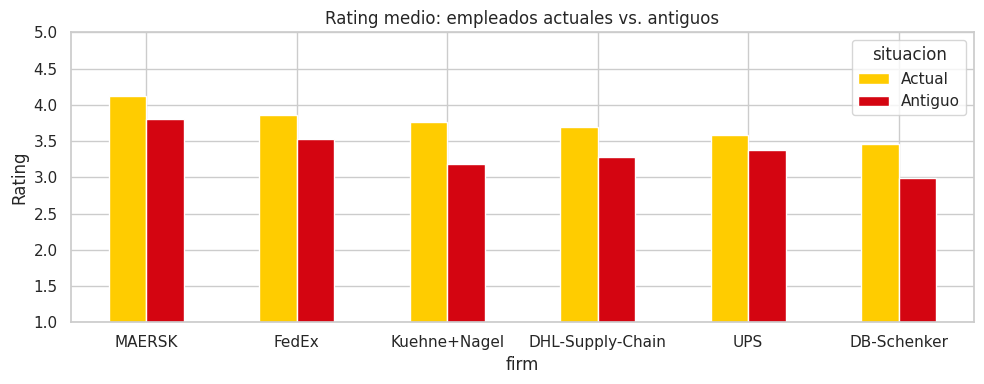

In [36]:
act_ant[['Actual', 'Antiguo']].plot(kind='bar', figsize=(10, 4), color=['#FFCC00', '#D40511'])
plt.title('Rating medio: empleados actuales vs. antiguos'); plt.ylabel('Rating'); plt.ylim(1, 5)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

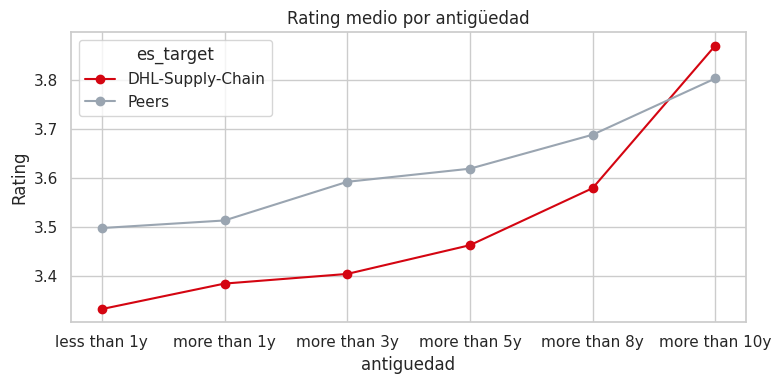

es_target,DHL-Supply-Chain,Peers
antiguedad,,
less than 1y,3.33,3.50
more than 1y,3.39,3.51
more than 3y,3.40,3.59
more than 5y,3.46,3.62
more than 8y,3.58,3.69
more than 10y,3.87,3.80


In [37]:
# Rating por antigüedad (solo reseñas que la informan)
ant_ord = ['less than 1y', 'more than 1y', 'more than 3y', 'more than 5y', 'more than 8y', 'more than 10y']
antig = (df[df['antiguedad'] != 'n/d']
         .pivot_table(index='antiguedad', columns='es_target', values='overall_rating', aggfunc='mean')
         .reindex(ant_ord))
antig.plot(marker='o', figsize=(8, 4), color=['#D40511', '#9aa5b1'])
plt.title('Rating medio por antigüedad'); plt.ylabel('Rating'); plt.tight_layout(); plt.show()
antig.round(2)

### 1.3 Evolución del rating

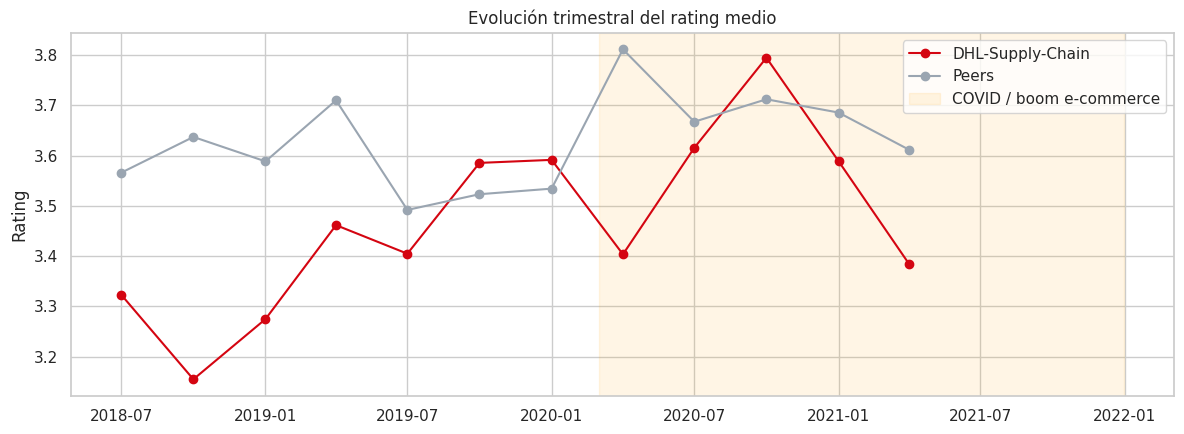

In [38]:
df['trimestre'] = df['date_review'].dt.to_period('Q').dt.to_timestamp()
evo = df.groupby(['trimestre', 'es_target'])['overall_rating'].agg(['mean', 'size']).reset_index()
# Trimestres con menos de 30 reseñas son ruido: se excluyen del gráfico
evo = evo[evo['size'] >= 30]

fig, ax = plt.subplots(figsize=(12, 4.5))
for grupo, c in [(TARGET, '#D40511'), ('Peers', '#9aa5b1')]:
    d = evo[evo['es_target'] == grupo]
    ax.plot(d['trimestre'], d['mean'], marker='o', label=grupo, color=c)
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-31'), alpha=0.1, color='orange', label='COVID / boom e-commerce')
ax.set_title('Evolución trimestral del rating medio'); ax.set_ylabel('Rating'); ax.legend()
plt.tight_layout(); plt.show()

In [39]:
por_anio = df.pivot_table(index='anio', columns='firm', values='overall_rating', aggfunc='mean')[orden]
print('Nº de reseñas por año:'); print(pd.crosstab(df['anio'], df['firm'])[orden], '\n')
por_anio.round(2)

Nº de reseñas por año:
firm  MAERSK  FedEx  Kuehne+Nagel  DHL-Supply-Chain  UPS  DB-Schenker
anio                                                                 
2018     124    144            20               136  207           55
2019     338    441           109               403  436          151
2020     429    673           178               512  652          188
2021     412    742           164               636  705          208 



firm,MAERSK,FedEx,Kuehne+Nagel,DHL-Supply-Chain,UPS,DB-Schenker
anio,,,,,,
2018,3.97,3.80,3.30,3.24,3.39,3.20
2019,3.97,3.69,3.41,3.43,3.39,3.07
2020,3.93,3.74,3.44,3.66,3.61,3.37
2021,4.06,3.70,3.74,3.51,3.49,3.25


### Conclusiones del EDA (ventana común jul-2018 → jun-2021)
- **Posición media-baja:** DHL Supply Chain (3,52) es 4ª de 6, empatada con Kuehne+Nagel y por delante solo de UPS y DB-Schenker. MAERSK (3,98) es el *benchmark* del sector. **Acción:** estudiar qué hace MAERSK distinto (secciones 3-4).
- **Polarización:** un 20 % de reseñas de DHL son de 1-2 estrellas (MAERSK ~10 %, FedEx ~15 %). Hay un grupo de empleados muy descontento → hay que identificar sus quejas en los cons.
- **Recomendación:** solo el 44 % recomienda DHL y un 26 % dice explícitamente que no (vs 18 % en FedEx). La reputación boca a boca afecta directamente a la atracción de talento.
- **Antigüedad:** DHL puntúa por debajo de los peers en todos los tramos de 1 a 8 años y solo supera a los peers con >10 años. **Acción:** el riesgo de fuga está en los perfiles de antigüedad media; hipótesis a validar con topics: carrera/promoción.
- **Actuales vs antiguos:** el gap (0,41) está en la media del sector → la pérdida de satisfacción al salir no es anómala.
- **Evolución:** DHL mejora en 2020 (3,66, pico del boom e-commerce/COVID) y retrocede en 2021 (3,51) mientras Kuehne+Nagel y MAERSK suben. Señal de alerta temprana.
- **Limitación:** DHL no tiene reseñas en el dataset tras jun-2021, por lo que todo el análisis se hace en la ventana común.

---
## 2. Sentimiento en pros y cons (control de calidad)

Uso `distilbert-base-uncased-finetuned-sst-2-english`: modelo transformer preentrenado, binario (POSITIVE/NEGATIVE), rápido y el sugerido en clase. **Por qué binario sirve aquí:** no queremos medir matices, sino comprobar que los textos de *pros* son mayoritariamente positivos y los de *cons* negativos. Si no lo fueran, habría un problema de limpieza o de datos que contaminaría los topics.

`truncation=True` corta en 512 tokens (las reseñas largas son pocas y su tono suele estar claro al principio).

In [40]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
print('GPU disponible:', torch.cuda.is_available())

clf = pipeline('sentiment-analysis',
               model='distilbert-base-uncased-finetuned-sst-2-english',
               device=device, truncation=True, max_length=512)

def predecir(textos, batch_size=64):
    out = clf(list(textos), batch_size=batch_size)
    return [o['label'] for o in out], [o['score'] for o in out]

# En Colab con GPU tarda ~2-4 min para ~16.000 textos
df['sent_pros'], df['score_pros'] = predecir(df['pros'])
df['sent_cons'], df['score_cons'] = predecir(df['cons'])
df.to_parquet('df_sentimiento.parquet')   # checkpoint para no recalcular

GPU disponible: True


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [41]:
calidad = (df.groupby('firm')
    .agg(pct_pros_positivos=('sent_pros', lambda s: (s == 'POSITIVE').mean() * 100),
         pct_cons_negativos=('sent_cons', lambda s: (s == 'NEGATIVE').mean() * 100))
    .round(1).loc[orden])
calidad.loc['TOTAL'] = [(df.sent_pros == 'POSITIVE').mean() * 100, (df.sent_cons == 'NEGATIVE').mean() * 100]
calidad.round(1)

,pct_pros_positivos,pct_cons_negativos
firm,,
MAERSK,92.6,77.4
FedEx,89.4,79.6
Kuehne+Nagel,93.2,83.9
DHL-Supply-Chain,87.8,81.7
UPS,88.1,83.8
DB-Schenker,86.0,86.0
TOTAL,89.2,81.5


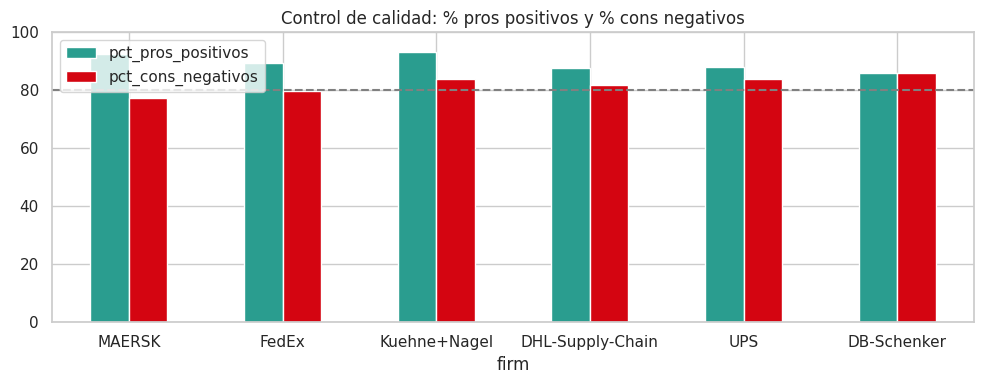

In [42]:
ax = calidad.drop('TOTAL').plot(kind='bar', figsize=(10, 4), color=['#2a9d8f', '#D40511'])
ax.axhline(80, ls='--', c='grey'); ax.set_ylim(0, 100)
ax.set_title('Control de calidad: % pros positivos y % cons negativos'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

### Casos discordantes

In [43]:
pd.set_option('display.max_colwidth', 200)
cons_pos = df[df['sent_cons'] == 'POSITIVE']
pros_neg = df[df['sent_pros'] == 'NEGATIVE']
print(f'Cons clasificados como POSITIVOS: {len(cons_pos):,} ({len(cons_pos)/len(df):.1%})')
print(f'Pros clasificados como NEGATIVOS: {len(pros_neg):,} ({len(pros_neg)/len(df):.1%})')

print('\n--- Cons POSITIVOS (muestra) ---')
display(cons_pos.sample(10, random_state=SEED)[['firm', 'cons', 'score_cons']])
print('\n--- Pros NEGATIVOS (muestra) ---')
display(pros_neg.sample(10, random_state=SEED)[['firm', 'pros', 'score_pros']])

Cons clasificados como POSITIVOS: 1,494 (18.5%)
Pros clasificados como NEGATIVOS: 867 (10.8%)

--- Cons POSITIVOS (muestra) ---


,firm,cons,score_cons
5109,MAERSK,Undergoing significant change program,0.990652
4877,MAERSK,"Management, bonus, opinions, many projects",0.998510
7060,UPS,I enjoy the work load,0.999791
5229,MAERSK,Job is a bit stressful sometimes especially when the urgency of requirements are needed in a not so convenient location. Good thing you have a team who can also assist you.,0.988707
5138,MAERSK,no cons for this company,0.995271
3098,FedEx,No downside from this company. Great company,0.997271
2705,FedEx,Long hours Transportation High Goals,0.991454
1735,DHL-Supply-Chain,Micro management by senior management,0.946079
1963,DHL-Supply-Chain,They aren’t disclosing that they have active cases of corona in the building before hiring,0.916808
1370,DHL-Supply-Chain,Nice place to work overall,0.999860



--- Pros NEGATIVOS (muestra) ---


,firm,pros,score_pros
2969,FedEx,"Supporting people are there, day shift job, one can apply for the desired role after completing 6 months in an organisation.",0.679492
3542,FedEx,Hourly pay Good for people without bills,0.622833
476,DB-Schenker,-Very international company -Tries to be inclusive -Flexible work schedules with Home Office possibilities -English is the working language,0.985788
7487,UPS,Given routine work within teams that was organized.,0.985774
3244,FedEx,None that i can think of,0.996586
5674,MAERSK,None. None. None. None. None.,0.999309
7958,UPS,nothing postive to say about UPS. They just rush in new employees because they don't even pay their employees.,0.998784
5661,MAERSK,Paid for courses and quick promotion,0.700294
174,DB-Schenker,"Weekly paycheck, overbearing or apathetic management, Blame culture, office politics, slackers get promoted hard workers get screwed.",0.998817
7734,UPS,"union protected, overtime after five hours of shift",0.948917


In [44]:
# Tipología de discordantes con reglas sencillas, para cuantificar lo que vemos al leerlos
patron_nada = r'^(none|nothing|no cons|n/?a|na|nil|not really|can\'?t think|cannot think|nothing really|no complaints)'
cons_pos = cons_pos.assign(
    tipo=np.select(
        [cons_pos['cons'].str.lower().str.match(patron_nada),
         cons_pos['cons'].str.split().str.len() <= 3],
        ['"No hay cons" / sin quejas', 'Texto muy corto (sin contexto)'],
        'Queja formulada en positivo / mixta'))
cons_pos['tipo'].value_counts(normalize=True).mul(100).round(1)

,proportion
tipo,
Queja formulada en positivo / mixta,88.8
"""No hay cons"" / sin quejas",11.2


**Interpretación (completar tras ejecutar):** la gran mayoría de los discordantes no son errores del modelo sino reseñas en las que el empleado escribe *"nothing"*, *"none"*, *"can't think of any"* en cons (el modelo lo lee como positivo), quejas formuladas con palabras amables (*"good company but low pay"*) o pros sarcásticos (*"plenty of overtime, no life"*).

**Decisión para el topic modeling:** los cons del tipo *"no hay cons"* no aportan un tema de queja → se excluyen del modelo de topics de cons (se cuentan aparte como señal positiva).

In [45]:
# Marcamos los cons vacíos de contenido para excluirlos del topic modeling de cons
df['cons_sin_queja'] = df['cons'].str.lower().str.match(patron_nada)
print(df.groupby('firm')['cons_sin_queja'].mean().mul(100).round(1).loc[orden])

firm
MAERSK              11.6
FedEx                7.0
Kuehne+Nagel         4.9
DHL-Supply-Chain     6.2
UPS                  2.6
DB-Schenker          3.8
Name: cons_sin_queja, dtype: float64


---
## 3. Topic modeling con BERTopic

**Por qué BERTopic:** usa *embeddings* de frases (entiende que "low pay" y "salary below market" son lo mismo), no necesita fijar a priori el número de temas y genera palabras clave interpretables con c-TF-IDF, lo que facilita traducir cada topic a una categoría de RRHH.

**Regla de comparabilidad:** un único modelo para los pros y otro para los cons, entrenados con las 6 empresas juntas. Así "Compensación" significa lo mismo en DHL que en UPS.

**Parámetros (con su justificación de negocio):**
- `all-MiniLM-L6-v2`: modelo de embeddings ligero y robusto en inglés; las reseñas son cortas.
- `min_cluster_size=30`, `min_samples=5` (~0,4 % de la muestra): evita micro-temas que RRHH no podría accionar, pero sin fusionar todas las quejas en 2-3 temas genéricos.
- `CountVectorizer` con *stopwords* en inglés y bigramas: "work life", "career growth" son conceptos clave. Sin `min_df`: en BERTopic el vectorizador se aplica sobre un documento por topic, así que un `min_df` alto falla cuando hay pocos topics.
- `UMAP random_state=SEED`: reproducibilidad.

In [46]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

emb_model = SentenceTransformer('all-MiniLM-L6-v2', device='cuda' if torch.cuda.is_available() else 'cpu')

def entrenar_bertopic(docs):
    embeddings = emb_model.encode(docs, show_progress_bar=True, batch_size=128)
    modelo = BERTopic(
        embedding_model=emb_model,
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=30, min_samples=5, metric='euclidean', cluster_selection_method='eom', prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words='english', ngram_range=(1, 2)),
        calculate_probabilities=False, verbose=True)
    topics, _ = modelo.fit_transform(docs, embeddings)
    return modelo, topics, embeddings

# PROS: todas las reseñas
docs_pros = df['pros'].tolist()
modelo_pros, topics_pros, emb_pros = entrenar_bertopic(docs_pros)

# CONS: excluimos los "no hay cons" (sección 2) porque no describen ninguna queja
mask_cons = ~df['cons_sin_queja']
docs_cons = df.loc[mask_cons, 'cons'].tolist()
modelo_cons, topics_cons, emb_cons = entrenar_bertopic(docs_cons)

print(f'Topics pros: {len(set(topics_pros)) - 1} | outliers: {np.mean(np.array(topics_pros) == -1):.1%}')
print(f'Topics cons: {len(set(topics_cons)) - 1} | outliers: {np.mean(np.array(topics_cons) == -1):.1%}')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

2026-10-17 19:00:16,901 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 19:00:34,412 - BERTopic - Dimensionality - Completed ✓
2026-10-17 19:00:34,413 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 19:00:34,703 - BERTopic - Cluster - Completed ✓
2026-10-17 19:00:34,710 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 19:00:34,903 - BERTopic - Representation - Completed ✓


Batches:   0%|          | 0/60 [00:00<?, ?it/s]

2026-10-17 19:00:37,519 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 19:00:53,686 - BERTopic - Dimensionality - Completed ✓
2026-10-17 19:00:53,687 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 19:00:53,961 - BERTopic - Cluster - Completed ✓
2026-10-17 19:00:53,966 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 19:00:54,225 - BERTopic - Representation - Completed ✓


Topics pros: 67 | outliers: 26.7%
Topics cons: 59 | outliers: 32.5%


### Tratamiento de outliers
HDBSCAN deja sin asignar (topic −1) las reseñas que no encajan claramente en ningún grupo. Suelen ser 30-50 %. **Decisión:** reasignarlas al topic más cercano por similitud de embeddings **solo si la similitud supera 0,4**; las demás quedan como *"Otros / genérico"*. Así no perdemos volumen (sesgaría los % por empresa) pero tampoco forzamos reseñas vagas ("good company") en categorías concretas.

In [47]:
def reducir_outliers(modelo, docs, topics, embeddings):
    nuevos = modelo.reduce_outliers(docs, topics, strategy='embeddings', embeddings=embeddings, threshold=0.4)
    modelo.update_topics(docs, topics=nuevos,
                         vectorizer_model=CountVectorizer(stop_words='english', ngram_range=(1, 2)))
    return nuevos

topics_pros = reducir_outliers(modelo_pros, docs_pros, topics_pros, emb_pros)
topics_cons = reducir_outliers(modelo_cons, docs_cons, topics_cons, emb_cons)
print(f'Outliers tras reasignar -> pros: {np.mean(np.array(topics_pros) == -1):.1%} | cons: {np.mean(np.array(topics_cons) == -1):.1%}')

2026-10-17 19:00:54,507 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-10-17 19:00:54,810 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers tras reasignar -> pros: 1.0% | cons: 4.5%


In [48]:
info_pros = modelo_pros.get_topic_info()
info_cons = modelo_cons.get_topic_info()
display(info_pros.head(25)[['Topic', 'Count', 'Name']])
display(info_cons.head(25)[['Topic', 'Count', 'Name']])

,Topic,Count,Name
0,-1,84,-1_money money_independent_money_forward
1,0,441,0_culture_work culture_great culture_company culture
2,1,306,1_balance_life balance_work life_life
3,2,315,2_place_place work_great place_good place
4,3,340,3_environment_work environment_atmosphere_friendly
5,4,297,4_people_people work_colleagues_great people
6,5,213,5_team_good team_great team_team work
7,6,259,6_pay_decent_money_decent pay
8,7,287,7_good pay_pay_benefits_benefits good
9,8,187,8_easy_easy job_easy work_job


,Topic,Count,Name
0,-1,339,-1_applicable_red_applicable applicable_people
1,0,872,0_pay_salary_low_benefits
2,1,422,1_hours_long_long hours_schedule
3,2,183,2_cons_cons cons_cons company_don cons
4,3,174,3_shift_shifts_night_night shift
5,4,158,4_balance_work life_life balance_life
6,5,214,5_management_hours_time_managers
7,6,231,6_hard work_hard_work_work hard
8,7,142,7_hot_cold_weather_summer
9,8,137,8_promotion_promotions_promoted_hike


In [49]:
modelo_cons.visualize_barchart(top_n_topics=12, n_words=6)

### Agrupación en categorías de negocio
Cada topic se asigna a una categoría de RRHH según sus palabras clave (diccionario de abajo). **Después se revisa a mano** la tabla resultante y se corrige con `OVERRIDE_PROS` / `OVERRIDE_CONS` cuando la regla se equivoca.

In [50]:
CATEGORIAS = {
    'Compensación y beneficios': ['pay', 'salary', 'wage', 'wages', 'benefits', 'bonus', 'money', 'compensation', 'raise', 'pension', 'insurance', 'discount', 'paid', 'hourly', 'rate'],
    'Conciliación y horarios':   ['hours', 'schedule', 'shift', 'shifts', 'balance', 'life balance', 'flexible', 'flexibility', 'overtime', 'weekend', 'weekends', 'time', 'holiday', 'vacation', 'night'],
    'Management y liderazgo':    ['management', 'manager', 'managers', 'supervisor', 'supervisors', 'leadership', 'boss', 'favoritism', 'favouritism', 'upper management'],
    'Carrera y desarrollo':      ['career', 'growth', 'promotion', 'progression', 'opportunities', 'opportunity', 'training', 'learning', 'learn', 'development', 'advancement', 'skills'],
    'Cultura y compañeros':      ['people', 'team', 'colleagues', 'culture', 'environment', 'friendly', 'coworkers', 'atmosphere', 'staff', 'family'],
    'Carga de trabajo y presión':['workload', 'pressure', 'stress', 'stressful', 'busy', 'understaffed', 'targets', 'fast', 'pace', 'physical', 'hard', 'heavy', 'tiring'],
    'Estabilidad y empresa':     ['company', 'global', 'stable', 'stability', 'security', 'job security', 'brand', 'international', 'big', 'large', 'reputation'],
    'Burocracia y procesos':     ['process', 'processes', 'bureaucracy', 'slow', 'systems', 'communication', 'politics', 'organization', 'structure', 'change'],
}

def categorizar(info, override):
    filas = []
    for _, r in info.iterrows():
        t = r['Topic']
        palabras = [w for w, _ in (modelo_tmp.get_topic(t) or [])][:10] if t != -1 else []
        if t == -1:
            cat = 'Otros / genérico'
        elif t in override:
            cat = override[t]
        else:
            puntos = {c: sum(w in kws for w in palabras[:6]) * 2 + sum(w in kws for w in palabras[6:]) for c, kws in CATEGORIAS.items()}
            cat = max(puntos, key=puntos.get) if max(puntos.values()) > 0 else 'Otros / genérico'
        filas.append({'Topic': t, 'Count': r['Count'], 'palabras': ', '.join(palabras[:8]), 'categoria': cat})
    return pd.DataFrame(filas)

# Revisión manual: si al leer la tabla un topic está mal asignado, se corrige aquí -> {topic_id: 'Categoría'}
OVERRIDE_PROS = {}
OVERRIDE_CONS = {}

modelo_tmp = modelo_pros; mapa_pros = categorizar(info_pros, OVERRIDE_PROS)
modelo_tmp = modelo_cons; mapa_cons = categorizar(info_cons, OVERRIDE_CONS)
pd.set_option('display.max_colwidth', 120)
display(mapa_pros); display(mapa_cons)

,Topic,Count,palabras,categoria
0,-1,84,,Otros / genérico
1,0,441,"culture, work culture, great culture, company culture, good culture, culture good, values, culture great",Cultura y compañeros
2,1,306,"balance, life balance, work life, life, work, balance good, good work, balance work",Conciliación y horarios
3,2,315,"place, place work, great place, good place, work, work great, great, nice place",Otros / genérico
4,3,340,"environment, work environment, atmosphere, friendly, nice, working environment, good environment, working",Cultura y compañeros
...,...,...,...,...
63,62,41,"promotion, promotions, promotion opportunities, good promotion, promoted, opportunity promotion, promote, opportunities",Carrera y desarrollo
64,63,35,"dhl, working dhl, dhl dhl, dhl great, dhl good, work dhl, foster, opportunities",Carrera y desarrollo
65,64,74,"growth, opportunity growth, room growth, opportunity, room, growth opportunities, growth opportunity, development",Carrera y desarrollo
66,65,40,"weekends, friday, monday, monday friday, pay weekends, weekend, days, days week",Conciliación y horarios


,Topic,Count,palabras,categoria
0,-1,339,,Otros / genérico
1,0,872,"pay, salary, low, benefits, low pay, low salary, average, compared",Compensación y beneficios
2,1,422,"hours, long, long hours, schedule, week, days, hours long, hours hours",Conciliación y horarios
3,2,183,"cons, cons cons, cons company, don cons, don, really, cons don, real cons",Otros / genérico
4,3,174,"shift, shifts, night, night shift, hour, shift work, hours, hour shifts",Conciliación y horarios
5,4,158,"balance, work life, life balance, life, work, balance work, poor work, life work",Conciliación y horarios
6,5,214,"management, hours, time, managers, work, don, hours management, upper",Management y liderazgo
7,6,231,"hard work, hard, work, work hard, physical, lot, work work, job",Carga de trabajo y presión
8,7,142,"hot, cold, weather, summer, temp, climate, hot summer, conditions",Otros / genérico
9,8,137,"promotion, promotions, promoted, hike, promote, slow, slow promotion, ceiling promotion",Carrera y desarrollo


In [51]:
# Llevamos la categoría a cada reseña
df['topic_pros'] = topics_pros
df['cat_pros'] = df['topic_pros'].map(mapa_pros.set_index('Topic')['categoria'])

df['topic_cons'] = np.nan
df.loc[mask_cons, 'topic_cons'] = topics_cons
df['cat_cons'] = df['topic_cons'].map(mapa_cons.set_index('Topic')['categoria'])
df.loc[~mask_cons, 'cat_cons'] = 'Sin quejas'

df.to_parquet('df_topics.parquet')   # checkpoint
CATS = list(CATEGORIAS.keys())

peso = pd.DataFrame({'% pros': df['cat_pros'].value_counts(normalize=True) * 100,
                     '% cons': df['cat_cons'].value_counts(normalize=True) * 100}).round(1).fillna(0)
peso

,% pros,% cons
Burocracia y procesos,1.6,6.0
Carga de trabajo y presión,1.1,9.5
Carrera y desarrollo,7.4,7.0
Compensación y beneficios,22.2,13.1
Conciliación y horarios,16.3,16.8
Cultura y compañeros,22.1,3.3
Estabilidad y empresa,10.4,3.2
Management y liderazgo,2.4,18.0
Otros / genérico,16.6,17.0
Sin quejas,0.0,6.1


---
## 4. Comparación con peers

Para cada empresa: % de reseñas cuyos pros / cons caen en cada categoría. Comparamos DHL con la **media de los peers** (media simple de las 5 empresas, para que UPS y FedEx, con más reseñas, no pesen más).

> **balance neto** = % que la destaca en pros − % que la menciona en cons. Un balance por encima de los peers es una fortaleza relativa; por debajo, una debilidad relativa.

In [52]:
def pct_por_empresa(col):
    t = pd.crosstab(df['firm'], df[col], normalize='index').mul(100)
    return t.reindex(columns=CATS, fill_value=0)

pros_pct, cons_pct = pct_por_empresa('cat_pros'), pct_por_empresa('cat_cons')
neto = pros_pct - cons_pct

comp = pd.DataFrame({
    'pros_DHL':  pros_pct.loc[TARGET],  'pros_peers':  pros_pct.loc[PEERS].mean(),
    'cons_DHL':  cons_pct.loc[TARGET],  'cons_peers':  cons_pct.loc[PEERS].mean(),
    'neto_DHL':  neto.loc[TARGET],      'neto_peers':  neto.loc[PEERS].mean()})
comp['gap_neto'] = comp['neto_DHL'] - comp['neto_peers']
comp = comp.round(1).sort_values('gap_neto')
comp

,pros_DHL,pros_peers,cons_DHL,cons_peers,neto_DHL,neto_peers,gap_neto
Conciliación y horarios,12.3,15.5,18.5,14.2,-6.2,1.3,-7.5
Cultura y compañeros,22.2,24.2,3.5,3.3,18.7,20.9,-2.2
Carga de trabajo y presión,0.5,1.1,7.4,8.3,-6.9,-7.2,0.3
Management y liderazgo,3.7,2.2,19.7,18.6,-16.0,-16.4,0.4
Estabilidad y empresa,11.5,11.9,2.5,3.8,9.0,8.1,0.8
Compensación y beneficios,21.4,20.1,14.2,14.2,7.2,5.8,1.4
Burocracia y procesos,1.8,1.8,5.0,7.1,-3.3,-5.2,2.0
Carrera y desarrollo,11.6,7.6,6.5,7.9,5.0,-0.3,5.4


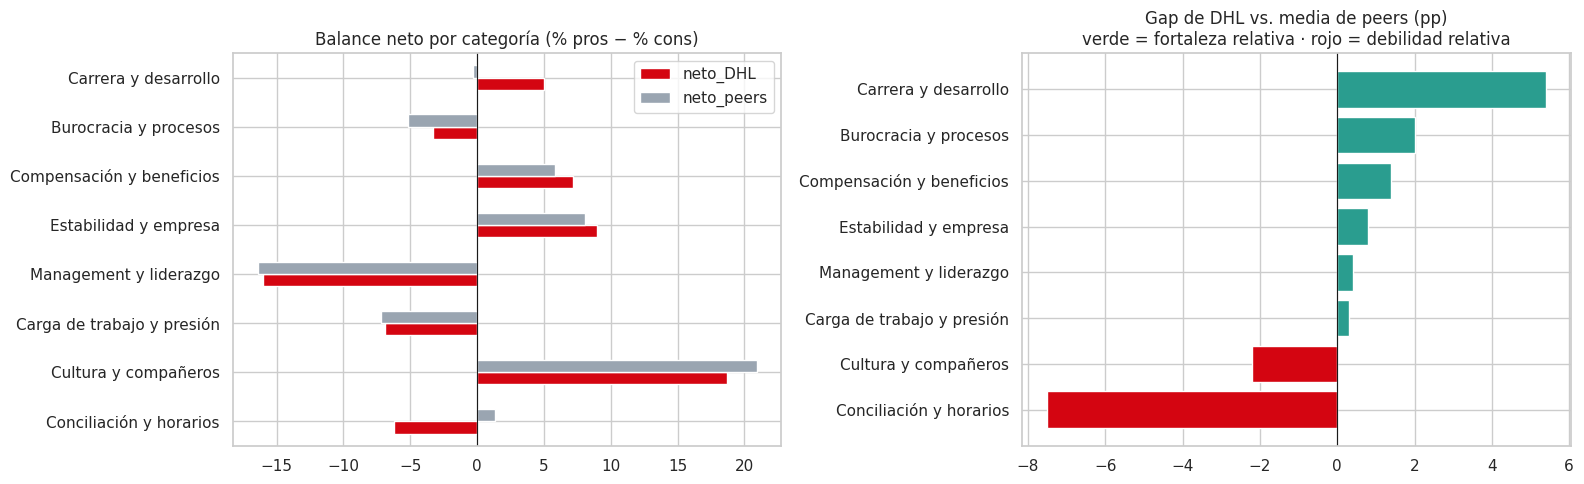

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
comp[['neto_DHL', 'neto_peers']].plot(kind='barh', ax=axes[0], color=['#D40511', '#9aa5b1'])
axes[0].axvline(0, c='k', lw=.8); axes[0].set_title('Balance neto por categoría (% pros − % cons)')
colores_gap = ['#2a9d8f' if v > 0 else '#D40511' for v in comp['gap_neto']]
axes[1].barh(comp.index, comp['gap_neto'], color=colores_gap); axes[1].axvline(0, c='k', lw=.8)
axes[1].set_title('Gap de DHL vs. media de peers (pp)\nverde = fortaleza relativa · rojo = debilidad relativa')
plt.tight_layout(); plt.show()

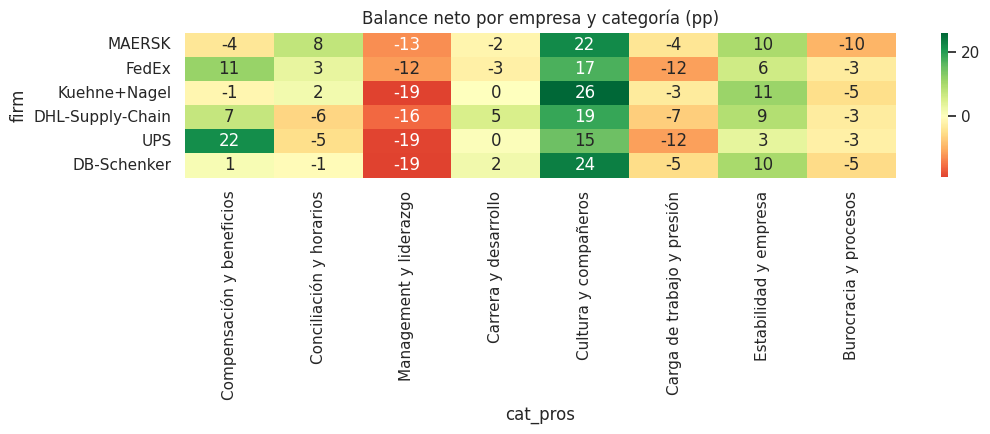

In [54]:
# Heatmap del balance neto por empresa: ¿quién es el referente en cada categoría?
plt.figure(figsize=(11, 4.5))
sns.heatmap(neto.loc[orden], annot=True, fmt='.0f', cmap='RdYlGn', center=0)
plt.title('Balance neto por empresa y categoría (pp)'); plt.tight_layout(); plt.show()

### Contraste con rating y recomendación
Si una categoría es de verdad un problema, las reseñas que se quejan de ella deberían puntuar peor.

In [55]:
contraste = (df[df['cat_cons'].isin(CATS)]
    .groupby(['cat_cons', 'es_target'])
    .agg(rating=('overall_rating', 'mean'), pct_no_recomienda=('recommend', lambda s: (s == 'x').mean() * 100), n=('firm', 'size'))
    .round(2).unstack())
contraste

rating       pct_no_recomienda         \
es_target                  DHL-Supply-Chain Peers  DHL-Supply-Chain  Peers   
cat_cons                                                                     
Burocracia y procesos                  3.60  3.90             22.35  14.65   
Carga de trabajo y presión             3.99  3.72             11.29  17.60   
Carrera y desarrollo                   3.50  3.75             27.27  16.63   
Compensación y beneficios              3.44  3.43             24.69  28.03   
Conciliación y horarios                3.57  3.74             20.19  17.34   
Cultura y compañeros                   3.34  3.34             35.59  34.78   
Estabilidad y empresa                  4.14  4.10              9.30  12.74   
Management y liderazgo                 2.76  2.93             49.85  42.20   

                                          n        
es_target                  DHL-Supply-Chain Peers  
cat_cons                                           
Burocracia y procesos                    85   396  
Carga de trabajo y presión              124   642  
Carrera y desarrollo                    110   457  
Compensación y beneficios               239   817  
Conciliación y horarios                 312  1044  
Cultura y compañeros                     59   207  
Estabilidad y empresa                    43   212  
Management y liderazgo                  333  1116

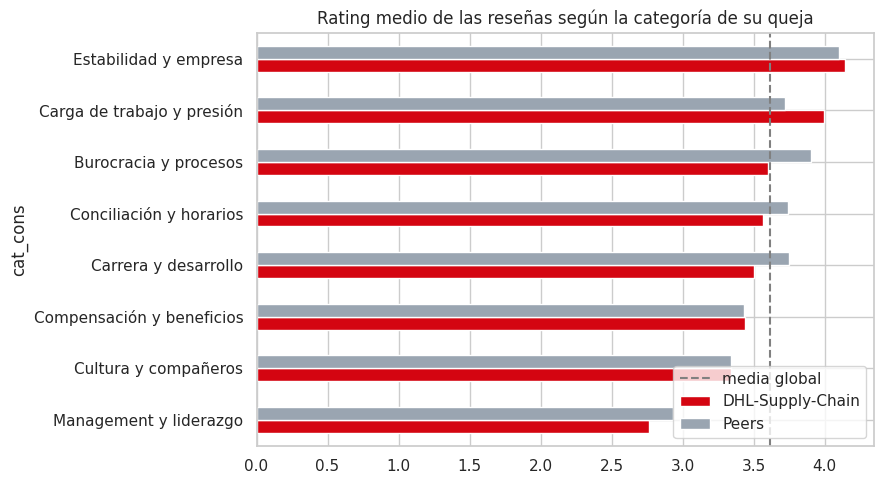

In [56]:
r = df[df['cat_cons'].isin(CATS)].groupby(['cat_cons', 'es_target'])['overall_rating'].mean().unstack()[[TARGET, 'Peers']]
r.sort_values(TARGET).plot(kind='barh', figsize=(9, 5), color=['#D40511', '#9aa5b1'])
plt.axvline(df['overall_rating'].mean(), ls='--', c='grey', label='media global')
plt.title('Rating medio de las reseñas según la categoría de su queja'); plt.legend(); plt.tight_layout(); plt.show()

---
## 5. Empleados actuales vs. antiguos

Los cons de quienes se han ido son, en la práctica, **motivos de salida**. Comparamos temas, no sentimiento (los antiguos siempre puntúan más bajo: sesgo de selección).

In [57]:
dhl = df[df['firm'] == TARGET]
act_vs_ant = (pd.crosstab(dhl['cat_cons'], dhl['situacion'], normalize='columns').mul(100)
              .reindex(CATS).round(1))
act_vs_ant['dif_antiguo_menos_actual'] = act_vs_ant['Antiguo'] - act_vs_ant['Actual']
act_vs_ant.sort_values('dif_antiguo_menos_actual', ascending=False)

situacion,Actual,Antiguo,dif_antiguo_menos_actual
cat_cons,,,
Management y liderazgo,18.7,21.2,2.5
Carrera y desarrollo,5.7,7.7,2.0
Conciliación y horarios,18.0,19.1,1.1
Cultura y compañeros,3.4,3.6,0.2
Carga de trabajo y presión,7.3,7.4,0.1
Compensación y beneficios,14.6,13.5,-1.1
Burocracia y procesos,5.7,4.2,-1.5
Estabilidad y empresa,3.5,1.3,-2.2


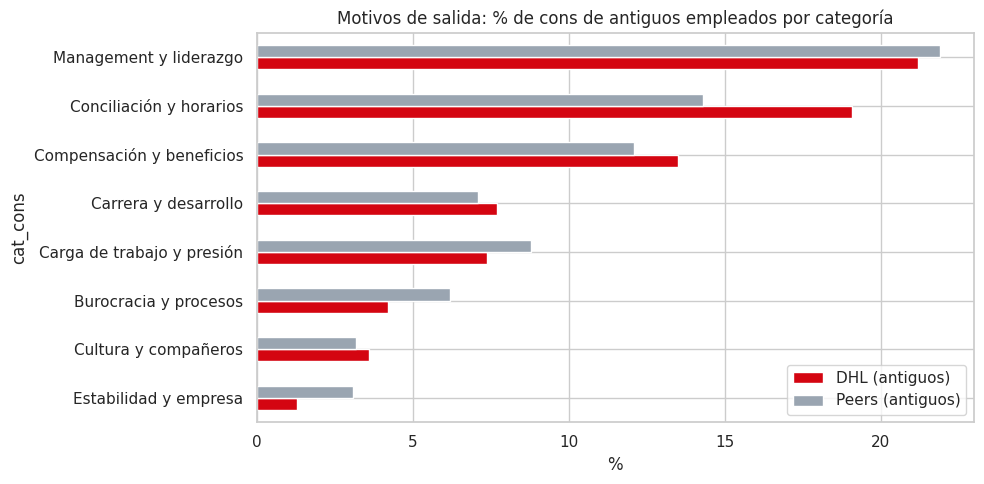

,DHL (antiguos),Peers (antiguos),gap
cat_cons,,,
Conciliación y horarios,19.1,14.3,4.8
Compensación y beneficios,13.5,12.1,1.5
Carrera y desarrollo,7.7,7.1,0.6
Cultura y compañeros,3.6,3.2,0.5
Management y liderazgo,21.2,21.9,-0.7
Carga de trabajo y presión,7.4,8.8,-1.4
Estabilidad y empresa,1.3,3.1,-1.8
Burocracia y procesos,4.2,6.2,-2.0


In [58]:
ant = df[df['situacion'] == 'Antiguo']
salida = pd.DataFrame({
    'DHL (antiguos)':   pd.crosstab(ant['firm'], ant['cat_cons'], normalize='index').mul(100).reindex(columns=CATS, fill_value=0).loc[TARGET],
    'Peers (antiguos)': pd.crosstab(ant['firm'], ant['cat_cons'], normalize='index').mul(100).reindex(columns=CATS, fill_value=0).loc[PEERS].mean()})
salida['gap'] = salida['DHL (antiguos)'] - salida['Peers (antiguos)']
salida = salida.round(1).sort_values('DHL (antiguos)', ascending=True)
salida[['DHL (antiguos)', 'Peers (antiguos)']].plot(kind='barh', figsize=(10, 5), color=['#D40511', '#9aa5b1'])
plt.title('Motivos de salida: % de cons de antiguos empleados por categoría'); plt.xlabel('%'); plt.tight_layout(); plt.show()
salida.sort_values('gap', ascending=False)

In [59]:
# Ejemplos reales de motivos de salida en DHL (para la presentación)
for cat in salida.sort_values('gap', ascending=False).index[:3]:
    print(f'\n=== {cat} ===')
    for t in ant[(ant['firm'] == TARGET) & (ant['cat_cons'] == cat)]['cons'].sample(3, random_state=SEED):
        print('-', t[:220])


=== Conciliación y horarios ===
- Was told to come in for training, verified it was the same day and time as given on my acceptance email with the hiring manager at orientation. I was the only person to show up that day, early nonetheless, and was unable
- Irregular hours hard get holidays
- - 30 minutes break, on a 10 hour Shift. You can barely eat, plus you have 120 employees going all at once, I have seen co-workers eat their food cold because they won’t have time to heat it up. They job itself is heavy a

=== Compensación y beneficios ===
- No Growth I. Terms of salary
- Only give raises per cost of living goin up so they say
- Benefits 1st year are pretty bad. You are basically paying almost everything with hsa or fsa

=== Carrera y desarrollo ===
- not enough proper training. working 72 hours in six days
- bad structure and no career support
- Fluctuations in business require mobility and flexibility.


---
## 6. Matriz de priorización

- **Eje X:** peso de la categoría en los cons de DHL (¿cuánto se habla de ello?).
- **Eje Y:** desventaja frente a peers = % cons DHL − % cons peers (¿estamos peor que el mercado?).

Cuadrante superior derecho = **prioridad alta** (mucho peso y peor que los peers).

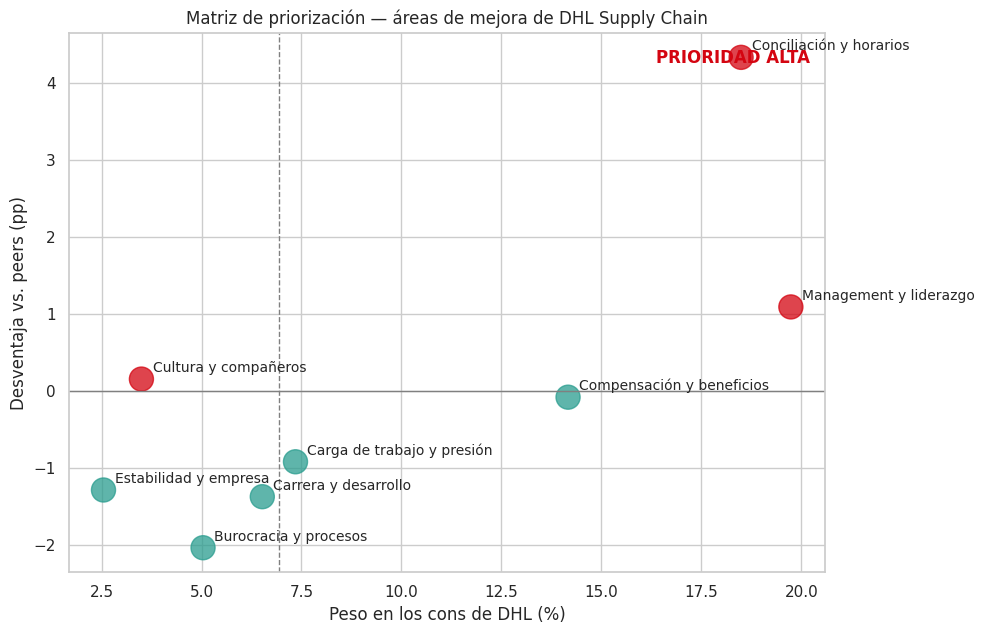

,peso_cons_DHL,desventaja_pp
cat_cons,,
Conciliación y horarios,18.5,4.3
Management y liderazgo,19.7,1.1
Cultura y compañeros,3.5,0.2
Compensación y beneficios,14.2,-0.1
Carga de trabajo y presión,7.4,-0.9
Estabilidad y empresa,2.5,-1.3
Carrera y desarrollo,6.5,-1.4
Burocracia y procesos,5.0,-2.0


In [60]:
matriz = pd.DataFrame({'peso_cons_DHL': cons_pct.loc[TARGET, CATS],
                       'desventaja_pp': cons_pct.loc[TARGET, CATS] - cons_pct.loc[PEERS, CATS].mean()})
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(matriz['peso_cons_DHL'], matriz['desventaja_pp'], s=300, c=np.where(matriz['desventaja_pp'] > 0, '#D40511', '#2a9d8f'), alpha=.75)
for cat, r in matriz.iterrows():
    ax.annotate(cat, (r['peso_cons_DHL'], r['desventaja_pp']), xytext=(8, 5), textcoords='offset points', fontsize=10)
ax.axhline(0, c='grey', lw=1); ax.axvline(matriz['peso_cons_DHL'].median(), c='grey', lw=1, ls='--')
ax.set_xlabel('Peso en los cons de DHL (%)'); ax.set_ylabel('Desventaja vs. peers (pp)')
ax.set_title('Matriz de priorización — áreas de mejora de DHL Supply Chain')
ax.text(.98, .97, 'PRIORIDAD ALTA', transform=ax.transAxes, ha='right', va='top', color='#D40511', weight='bold')
plt.tight_layout(); plt.show()
matriz.round(1).sort_values('desventaja_pp', ascending=False)

### Extra: evolución pre vs. post 2020

In [61]:
df['periodo'] = np.where(df['anio'] < 2020, 'Pre-2020', '2020-2021')
evo_cat = (df[df['cat_cons'].isin(CATS)]
           .groupby(['es_target', 'periodo'])['cat_cons'].value_counts(normalize=True).mul(100)
           .unstack().T.round(1))
evo_cat

es_target                  DHL-Supply-Chain              Peers         
periodo                           2020-2021 Pre-2020 2020-2021 Pre-2020
cat_cons                                                               
Burocracia y procesos                   6.3      7.0       8.3      7.6
Carga de trabajo y presión              9.1     10.4      14.1     11.0
Carrera y desarrollo                    8.0      9.4       8.3     11.6
Compensación y beneficios              18.9     17.1      16.3     17.5
Conciliación y horarios                25.6     20.2      22.4     19.1
Cultura y compañeros                    3.1      7.5       4.1      4.6
Estabilidad y empresa                   3.7      2.4       4.3      4.4
Management y liderazgo                 25.3     26.0      22.2     24.2

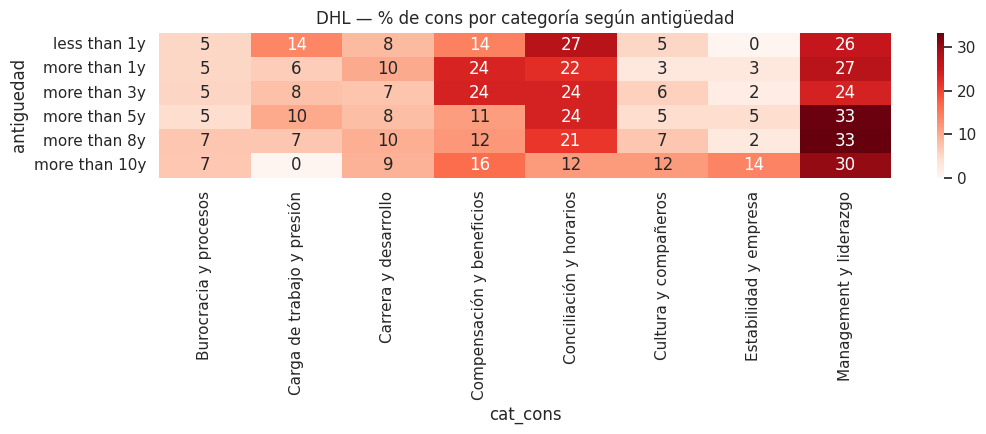

In [62]:
# Extra: categoría de queja por antigüedad en DHL (¿qué preocupa a cada etapa?)
ant_ord2 = ['less than 1y', 'more than 1y', 'more than 3y', 'more than 5y', 'more than 8y', 'more than 10y']
x = dhl[dhl['antiguedad'].isin(ant_ord2) & dhl['cat_cons'].isin(CATS)]
plt.figure(figsize=(11, 4.5))
sns.heatmap(pd.crosstab(x['antiguedad'], x['cat_cons'], normalize='index').mul(100).reindex(ant_ord2),
            annot=True, fmt='.0f', cmap='Reds')
plt.title('DHL — % de cons por categoría según antigüedad'); plt.tight_layout(); plt.show()

---
## 7. Conclusiones y recomendaciones para RRHH

*(Se redactan con los resultados ejecutados.)*

**Puntos fuertes (para employer branding):**
- …

**Áreas de mejora prioritarias:**
- …

**Recomendaciones (máx. 3):**
1. **Retención:** …
2. **Atracción:** …
3. **Gestión:** …

**Limitaciones:**
- Glassdoor no es representativo: sobrerrepresenta a empleados muy satisfechos o muy descontentos.
- Mezcla de países, áreas (almacén, oficina, transporte) y puestos; DHL Supply Chain es solo una entidad del grupo.
- Los topics son aproximados: una reseña puede tratar varios temas pero se asigna a uno solo.
- Ventana temporal limitada a jul-2018 → jun-2021 por falta de reseñas de DHL posteriores.

**Próximos pasos:** clasificación multi-etiqueta (zero-shot) para captar varios temas por reseña, análisis por país/puesto, y encuesta interna para validar los hallazgos.